In [1]:
import pandas as pd
from Bio import SeqIO
from skbio.diversity import alpha
import math

In [2]:
seq = list(SeqIO.parse('data/cox2_th_test/cox2_th_test-qiime.fa', 'fasta'))
accessions = [record.id for record in seq]
print(f'# of sequence in db: {len(accessions)}')
df = pd.read_csv('data/cox2_th_test/cox2_th_test-meta.tsv', index_col='accession', sep='\t')
meta = df[df.index.isin(accessions)]
meta

# of sequence in db: 1256


,creation_date,title,authors,sequence_length,organism_name,tax_id_x,cox2_start,cox2_end,cox2_strand,organism_name_sanitized,...,trimed_seq_len,tax_id_y,species,domain,kingdom,phylum,class,order,family,genus
accession,,,,,,,,,,,,,,,,,,,,,
KM819519.1,27-JAN-2015,Pythiogeton ramosum isolate SC2.7.2 cytochrome...,"Le,D.P., Smith,M.K. and Aitken,E.",614,Pythiogeton ramosum,1217586,<0,>614,1.0,Pythiogeton ramosum,...,307,1217586.0,Pythiogeton ramosum,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiogetonaceae,Pythiogeton
LC028397.1,01-NOV-2016,Pythium barbulae mitochondrial cox2 gene for c...,"Ueta,S. and Tojo,M.",613,Globisporangium barbulae,1629122,<0,>613,1.0,Globisporangium barbulae,...,306,1629122.0,Globisporangium barbulae,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium
MN381730.1,15-APR-2020,Globisporangium spinosum strain SQ00903-1 cyto...,"Huo,C., Zhao,Z. and Cao,J.",604,Globisporangium spinosum,2125998,<0,>604,1.0,Globisporangium spinosum,...,303,2125998.0,Globisporangium spinosum,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium
KP723171.1,16-SEP-2015,Globisporangium kandovanense voucher CCTU 1813...,"Chenari Bouket,A., Arzanlou,M., Tojo,M. and Ba...",587,Globisporangium kandovanense,1632203,24,>587,1.0,Globisporangium kandovanense,...,301,1632203.0,Globisporangium kandovanense,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium
GU071804.1,25-JUL-2016,Pythium irregulare strain STE-U6769 cytochrome...,"Spies,C.F., Mazzola,M., Botha,W.J., Langenhove...",596,Globisporangium irregulare,36331,<0,>596,1.0,Globisporangium irregulare,...,299,36331.0,Globisporangium irregulare,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MK602199.1,29-APR-2020,Globisporangium spinosum isolate C9 cytochrome...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium spinosum,2125998,<0,>518,1.0,Globisporangium spinosum,...,211,2125998.0,Globisporangium spinosum,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium
MK602203.1,29-APR-2020,Globisporangium irregulare isolate C13 cytochr...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium irregulare,36331,<0,>518,1.0,Globisporangium irregulare,...,211,36331.0,Globisporangium irregulare,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium
MK602204.1,29-APR-2020,Globisporangium irregulare isolate C14 cytochr...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium irregulare,36331,<0,>518,1.0,Globisporangium irregulare,...,211,36331.0,Globisporangium irregulare,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium


# Taxonomic Richness

<Axes: xlabel='species'>

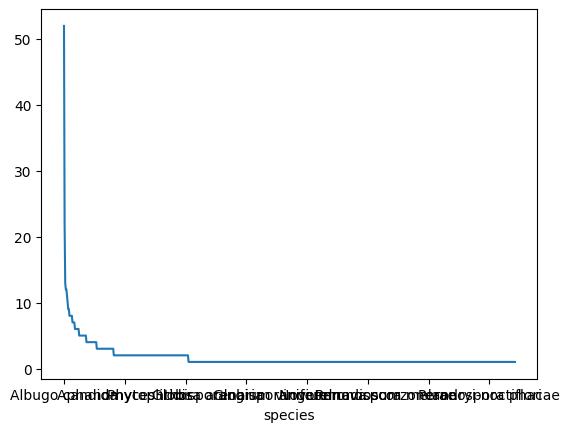

In [3]:
species_counts = meta['species'].value_counts(sort=True, ascending=False)
species_counts.plot.line()

<Axes: xlabel='species'>

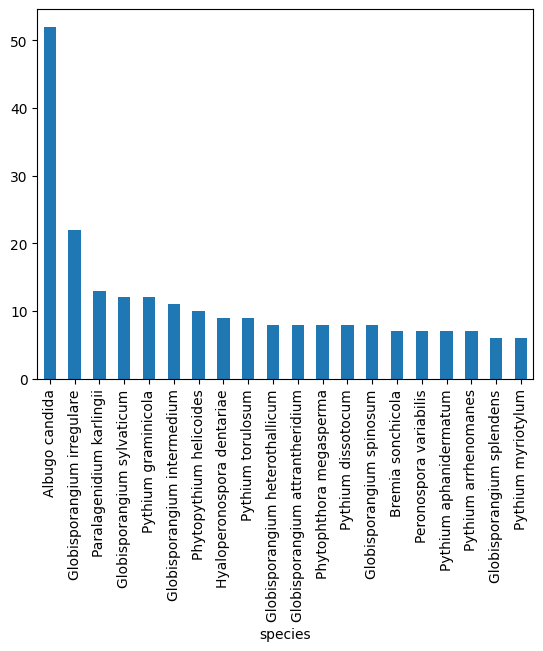

In [4]:
species_counts[:20].plot.bar()

# Taxonomic evenness

**Shannon index**: Entropy; Evenness: % of max. entropy reached

**Dominance index**: Probability that 2 sequences are from the same species

In [5]:
shannon = alpha.shannon(species_counts)
h_max = math.log(len(species_counts))
evenness = shannon / h_max
dominance = alpha.dominance(species_counts)

print(f'Shannon index: {shannon}; H_max: {h_max}; Evenness: {evenness}')
print(f'Dominance: {dominance}')

Shannon index: 6.242413920737387; H_max: 6.610696044717759; Evenness: 0.9442899625865198
Dominance: 0.0042154347032333965
